# RA3 — Data Analytics, visualizações e Machine Learning
### Vendas, promoções e sobra de produção em uma rede de padarias
**Equipe:** Helena Picinin, Marco Capote, Raissa Queiroz e Rafael Sene
**Disciplina:** Data Analytics (PjBL) — Sistemas de Informação, 6º período | **Professora:** Marina de Lara
**Continuação:** RA1 (ingestão e limpeza) → RA2 (simulação de streaming) → RA3 (estatística, visualizações e previsão)

**Pergunta de negócio:** como comportamento de vendas, calendário, clima, promoções e sobra podem apoiar as decisões de produção nas três lojas?

Trabalhamos com o mesmo dataset sintético do RA1 (2023–2024, 3 lojas, 7 categorias, 35 produtos). O notebook segue os cinco requisitos do RA3:

| Seção | Requisito do RA3 | O que é feito |
|---|---|---|
| 0 | — | Carrega a base preparada no RA1 (ou reconstrói a partir do CSV bruto) |
| 1 | Análise estatística descritiva | Média, mediana, desvio-padrão, amplitude, quartis, assimetria e frequências |
| 2 | Visualização e interpretação | 7 gráficos ligados às perguntas P1–P4, cada um com interpretação |
| 3 | Amostragem e representatividade | Origem, abrangência, adequação e vieses da base |
| 4 | Machine Learning | Regressão (Random Forest) com divisão temporal e comparação com uma referência simples |
| 5 | — | Testes automáticos de consistência (sem vazamento de dados, divisão correta, arquivos gerados) |
| 6 | Conclusões | Síntese e exportação de `outputs/ra3_resultados.md` |

**Como executar:** `python -m pip install -r requirements.txt` e depois *Kernel > Restart & Run All* (cerca de 30 segundos). Os gráficos são salvos em `outputs/graficos/` e o resumo em `outputs/ra3_resultados.md`.

**Atenção:** totais de `Quantity` representam unidades efetivamente vendidas. Os dados não informam quantas vendas foram perdidas por falta de estoque; portanto, não são uma medida completa da demanda.

## 0. Preparação e origem dos dados

O código procura, nesta ordem, `data/processed/bakery_sales_preparado.csv` (produto do RA1) e `data/raw/bakery_sales_dataset.csv` (dataset bruto). Se ambos faltarem, tenta baixar a cópia pública do Kaggle usada no RA1. Caso o download falhe, baixe o arquivo manualmente pelo link da fonte e coloque-o em um dos caminhos indicados.

Quando parte do CSV bruto, o notebook **reproduz as decisões de preparo do RA1**: remove apenas linhas 100% idênticas (a base não tem nenhuma; um pedido com vários produtos continua ocupando uma linha por produto), preenche `Festival` e `Promotion_Type` vazios, preserva os descontos observados e cria `Discount_Without_Promotion` e `Timestamp`.

In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True, 'grid.alpha': .20,
                     'savefig.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11})
COR = '#3488a5'          # cor principal dos gráficos
COR_DESTAQUE = '#d9822b'  # destaque (maior valor, média, previsão)
PASTA_SAIDA = Path('outputs')
PASTA_GRAFICOS = PASTA_SAIDA / 'graficos'
PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)


def br(valor, casas=0):
    """Formata números no padrão brasileiro (1.234,5)."""
    texto = f'{valor:,.{casas}f}'
    return texto.replace(',', 'X').replace('.', ',').replace('X', '.')


URL_KAGGLE = ('https://www.kaggle.com/api/v1/datasets/download/'
              'sdcloud/historical-bakery-sales-dataset/bakery_sales_dataset.csv')

# Colab, diretório do projeto ou notebook executado de dentro de uma subpasta.
raizes = [Path('.'), Path('..'), Path('/content')]
possiveis_preparados = [r / 'data/processed/bakery_sales_preparado.csv' for r in raizes]
possiveis_brutos = ([r / 'data/raw/bakery_sales_dataset.csv' for r in raizes] +
                    [r / 'bakery_sales_dataset.csv' for r in raizes])
preparado = next((p for p in possiveis_preparados if p.is_file()), None)
bruto = next((p for p in possiveis_brutos if p.is_file()), None)
if preparado is None and bruto is None:
    bruto = Path('data/raw/bakery_sales_dataset.csv')
    bruto.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_KAGGLE, bruto)
        print('Dataset público baixado:', bruto)
    except Exception as ex:
        raise FileNotFoundError(
            'Não encontrei a base preparada nem a bruta. Baixe manualmente o arquivo '
            'bakery_sales_dataset.csv do Kaggle e salve em data/raw/; '
            'ou copie o CSV do RA1 para data/processed/. Detalhe da tentativa: '
            + str(ex)) from ex

if preparado is not None:
    df = pd.read_csv(preparado, encoding='utf-8-sig', parse_dates=['Date', 'Timestamp'])
    print('Usando CSV preparado no RA1:', preparado)
else:
    df = pd.read_csv(bruto, encoding='utf-8-sig')
    print('Reconstruindo o preparo do RA1 a partir de:', bruto)
    df = df.drop_duplicates().copy()   # só linhas 100% idênticas (nenhuma nesta base)
    df['Festival'] = df['Festival'].fillna('No Festival')
    df['Promotion_Type'] = df['Promotion_Type'].fillna('No Promotion')
    df['Discount_Without_Promotion'] = (
        (df['Promotion_Applied'] == 'No') & (df['Discount_Percentage'] > 0))
    df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')
    df['Time'] = pd.to_datetime(df['Time'], format='%H:%M').dt.strftime('%H:%M')
    for nome in ['Loyalty_Member', 'Weekend', 'Promotion_Applied']:
        df[nome] = df[nome].map({'Yes': True, 'No': False})
    df['Timestamp'] = pd.to_datetime(df['Date'].dt.strftime('%Y-%m-%d') + ' ' + df['Time'])
    df = df.sort_values(['Timestamp', 'Order_ID', 'Product']).reset_index(drop=True)

# Robustez caso o CSV processado tenha representações textuais dos booleanos.
for nome in ['Loyalty_Member', 'Weekend', 'Promotion_Applied', 'Discount_Without_Promotion']:
    if nome in df and df[nome].dtype == object:
        df[nome] = df[nome].astype(str).str.lower().map({'true': True, 'false': False, 'yes': True, 'no': False})

obrigatorias = ['Date', 'Timestamp', 'Order_ID', 'Product', 'Store_ID', 'Category', 'Quantity',
                'Total_Bill', 'Profit', 'Waste_Pct', 'Unsold_Units', 'Perishability', 'Hour',
                'Promotion_Type', 'Promotion_Applied', 'Discount_Percentage', 'Festival',
                'Weather', 'Temperature']
faltando = [c for c in obrigatorias if c not in df]
assert not faltando, f'Colunas ausentes: {faltando}'
assert df['Date'].notna().all() and df['Quantity'].ge(0).all()
assert not df.duplicated(['Order_ID', 'Product']).any(), 'Revise a chave (Order_ID, Product).'
assert df['Total_Bill'].notna().all() and df['Profit'].notna().all()
print(f'Base: {br(len(df))} registros, {df.shape[1]} colunas; {df.Date.min():%d/%m/%Y} a {df.Date.max():%d/%m/%Y}')
print('Lojas:', sorted(df['Store_ID'].unique()), '| Categorias:', df['Category'].nunique(),
      '| Produtos:', df['Product'].nunique(), '| Pedidos:', br(df['Order_ID'].nunique()))
display(df[['Date', 'Store_ID', 'Category', 'Quantity', 'Total_Bill', 'Waste_Pct']].head())

Usando CSV preparado no RA1: data\processed\bakery_sales_preparado.csv
Base: 19.321 registros, 42 colunas; 01/01/2023 a 31/12/2024
Lojas: ['ST01', 'ST02', 'ST03'] | Categorias: 7 | Produtos: 35 | Pedidos: 6.576


,Date,Store_ID,Category,Quantity,Total_Bill,Waste_Pct
0,2023-01-01,ST01,Bread & Daily,1,35.96,12.5
1,2023-01-01,ST01,Pastry & Sweet,3,123.93,25.0
2,2023-01-01,ST01,Savoury Bakery,7,159.46,12.5
3,2023-01-01,ST03,Pastry & Sweet,1,48.22,50.0
4,2023-01-01,ST03,Pastry & Sweet,1,31.65,50.0


## 1. Estatística descritiva

- **Tendência central:** média e mediana de unidades por item vendido, faturamento por item, lucro por item e percentual de sobra por registro.
- **Dispersão:** desvio-padrão, mínimo, máximo, amplitude e quartis (Q1 e Q3).
- **Distribuição:** assimetria, frequências de quantidade e de categoria e histogramas (Gráfico 1).

Usamos média **e** mediana porque faturamento e lucro são assimétricos: poucos itens de valor alto puxam a média para cima, e a mediana mostra melhor o item típico.

**Cuidado metodológico:** `Waste_Pct` é uma porcentagem do **lote** registrada em cada linha de venda. Não somamos `Unsold_Units` entre linhas como se fossem lotes independentes, pois o dataset não tem identificador de lote.

In [2]:
variaveis = ['Quantity', 'Total_Bill', 'Profit', 'Waste_Pct']
estat = df[variaveis].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
estat['amplitude'] = estat['max'] - estat['min']
estat['q1'] = df[variaveis].quantile(.25)
estat['q3'] = df[variaveis].quantile(.75)
estat['assimetria'] = df[variaveis].skew()
estat = estat[['count', 'mean', 'median', 'std', 'min', 'q1', 'q3', 'max', 'amplitude', 'assimetria']]
display(estat.round(2).rename(columns={'mean': 'média', 'median': 'mediana', 'std': 'desvio-padrão'}))

frequencia_categorias = df['Category'].value_counts().rename_axis('Categoria').to_frame('Registros')
frequencia_categorias['%'] = 100 * frequencia_categorias['Registros'] / len(df)
display(frequencia_categorias.round(1))

freq_qtd = df['Quantity'].value_counts().sort_index()
pct_qtd = 100 * freq_qtd / len(df)
pct_ate_2 = 100 * df['Quantity'].le(2).mean()
print('Frequência por quantidade de unidades no item (10 primeiros valores):')
display(pd.DataFrame({'Registros': freq_qtd, '%': pct_qtd.round(1)}).head(10))

freq_sobra = 100 * df['Waste_Pct'].round(1).value_counts(normalize=True)
pct_sobra_50 = freq_sobra.get(50.0, 0)
print('Valores mais frequentes de Waste_Pct (% dos registros):')
display(freq_sobra.head(6).round(1).rename_axis('Waste_Pct').to_frame('% dos registros'))

print(f"Leitura: {br(pct_qtd.loc[1], 1)}% dos itens têm 1 unidade e {br(pct_ate_2, 1)}% têm até 2 unidades; "
      f"a média ({br(estat.loc['Quantity', 'mean'], 2)}) fica acima da mediana (2) por causa de poucos itens com muitas unidades.")
print(f"Faturamento por item: metade fica entre {br(estat.loc['Total_Bill', 'q1'], 2)} e {br(estat.loc['Total_Bill', 'q3'], 2)} (Q1–Q3), "
      f"mas o máximo chega a {br(estat.loc['Total_Bill', 'max'], 2)} — assimetria de {br(estat.loc['Total_Bill', 'assimetria'], 2)}.")
print(f"Waste_Pct assume poucos valores (50%, 33,3%, 25%, 20%...): os lotes são pequenos. "
      f"{br(pct_sobra_50, 1)}% dos registros têm 50% de sobra, por isso Q3 e máximo coincidem em 50%.")

,count,média,mediana,desvio-padrão,min,q1,q3,max,amplitude,assimetria
Quantity,19321.0,2.23,2.00,1.78,1.00,1.00,3.00,20.00,19.00,2.61
Total_Bill,19321.0,139.27,82.80,157.77,13.12,52.12,146.54,1885.96,1872.84,3.43
Profit,19321.0,59.20,36.76,65.24,-0.55,20.69,65.92,767.60,768.15,3.12
Waste_Pct,19321.0,34.12,33.30,12.73,4.20,25.00,50.00,50.00,45.80,-0.01


,Registros,%
Categoria,,
Dairy & Spreads,3620,18.7
Pastry & Sweet,3577,18.5
Beverages,3219,16.7
Indian Bakery,3058,15.8
Bread & Daily,2648,13.7
Cakes,2189,11.3
Savoury Bakery,1010,5.2


Frequência por quantidade de unidades no item (10 primeiros valores):


,Registros,%
Quantity,,
1,8426,43.6
2,5985,31.0
3,1856,9.6
4,1243,6.4
5,638,3.3
6,461,2.4
7,230,1.2
8,208,1.1
9,110,0.6


Valores mais frequentes de Waste_Pct (% dos registros):


,% dos registros
Waste_Pct,
50.0,33.3
33.3,29.0
25.0,13.8
20.0,8.7
16.7,4.3
14.3,2.7


Leitura: 43,6% dos itens têm 1 unidade e 74,6% têm até 2 unidades; a média (2,23) fica acima da mediana (2) por causa de poucos itens com muitas unidades.
Faturamento por item: metade fica entre 52,12 e 146,54 (Q1–Q3), mas o máximo chega a 1.885,96 — assimetria de 3,43.
Waste_Pct assume poucos valores (50%, 33,3%, 25%, 20%...): os lotes são pequenos. 33,3% dos registros têm 50% de sobra, por isso Q3 e máximo coincidem em 50%.


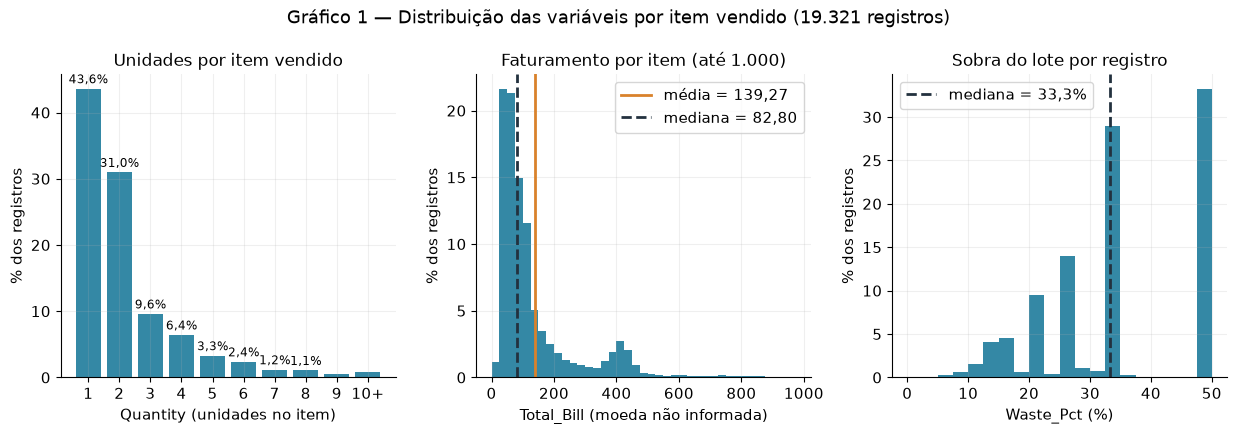

Observação: 76 itens com faturamento acima de 1.000 ficaram fora do eixo do histograma central, mas entram nas estatísticas.
Interpretação: quantidade e faturamento têm cauda longa à direita (muitos itens pequenos e poucos grandes); a sobra se concentra em poucos valores fixos, típicos de lotes pequenos.


In [3]:
# Gráfico 1 — distribuição das três variáveis principais.
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.4))

qtd = df['Quantity'].clip(upper=10).value_counts(normalize=True).sort_index() * 100
rot_qtd = [str(i) for i in qtd.index[:-1]] + ['10+']
axes[0].bar(rot_qtd, qtd.values, color=COR)
for x, v in zip(rot_qtd, qtd.values):
    if v >= 1:
        axes[0].text(x, v + .8, br(v, 1) + '%', ha='center', fontsize=8.5)
axes[0].set(title='Unidades por item vendido', xlabel='Quantity (unidades no item)', ylabel='% dos registros')

axes[1].hist(df['Total_Bill'], bins=np.arange(0, 1000, 25), color=COR,
             weights=np.full(len(df), 100 / len(df)))
axes[1].axvline(estat.loc['Total_Bill', 'mean'], color=COR_DESTAQUE, lw=2, label=f"média = {br(estat.loc['Total_Bill', 'mean'], 2)}")
axes[1].axvline(estat.loc['Total_Bill', 'median'], color='#23313e', lw=2, ls='--', label=f"mediana = {br(estat.loc['Total_Bill', 'median'], 2)}")
axes[1].set(title='Faturamento por item (até 1.000)', xlabel='Total_Bill (moeda não informada)', ylabel='% dos registros')
axes[1].legend()

axes[2].hist(df['Waste_Pct'], bins=np.arange(0, 52.5, 2.5), color=COR,
             weights=np.full(len(df), 100 / len(df)))
axes[2].axvline(estat.loc['Waste_Pct', 'median'], color='#23313e', lw=2, ls='--', label=f"mediana = {br(estat.loc['Waste_Pct', 'median'], 1)}%")
axes[2].set(title='Sobra do lote por registro', xlabel='Waste_Pct (%)', ylabel='% dos registros')
axes[2].legend(loc='upper left')

fig.suptitle('Gráfico 1 — Distribuição das variáveis por item vendido (19.321 registros)', fontsize=13)
fig.tight_layout(); fig.savefig(PASTA_GRAFICOS / '01_distribuicao_variaveis.png'); plt.show()
fora = df['Total_Bill'].gt(1000).sum()
print(f'Observação: {fora} itens com faturamento acima de 1.000 ficaram fora do eixo do histograma central, mas entram nas estatísticas.')
print('Interpretação: quantidade e faturamento têm cauda longa à direita (muitos itens pequenos e poucos grandes);'
      ' a sobra se concentra em poucos valores fixos, típicos de lotes pequenos.')

## 2. Gráficos com interpretação — perguntas P1 a P4

As visualizações cobrem horários e dias (P1), clima e festivais (P2), promoções (P3) e sobra (P4). Cada figura tem título, eixos com unidades e uma interpretação impressa logo abaixo. As agregações respeitam o nível dos dados: somamos `Quantity` por dia ou hora; comparamos dias usando **médias por data** (cada data entra uma vez); e tratamos `Waste_Pct` apenas como atributo do registro.

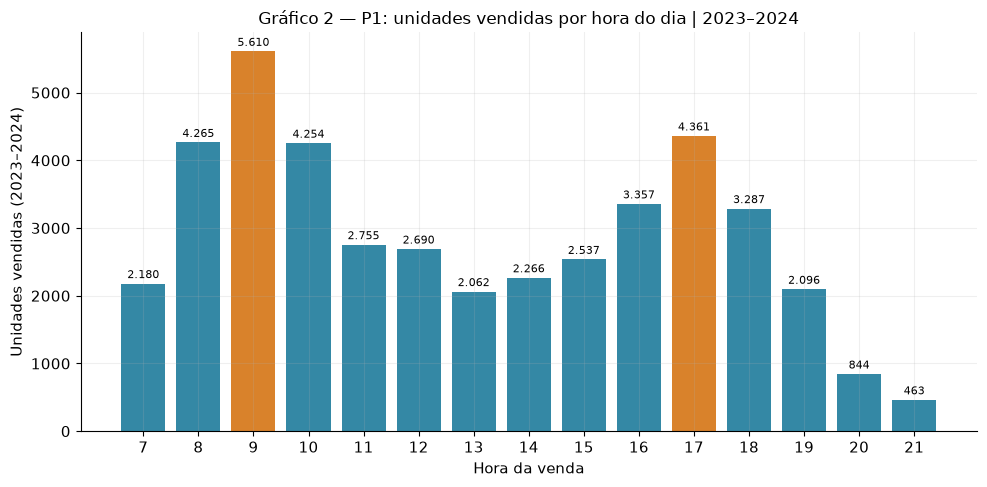

P1: pico às 9h (5.610 unidades) e segundo pico às 17h (4.361).
As faixas 8h–10h e 16h–18h concentram 32,8% e 25,6% das unidades vendidas.
Interpretação: a produção pode ser escalonada em duas fornadas principais (antes das 8h e antes das 16h); são vendas registradas, não demanda não atendida.


In [4]:
# P1 — horários: unidades vendidas por hora (soma de Quantity, não contagem de linhas).
por_hora = df.groupby('Hour').agg(unidades=('Quantity', 'sum'), faturamento=('Total_Bill', 'sum')).sort_index()
hora_pico = int(por_hora['unidades'].idxmax())
tarde = por_hora.loc[13:]
hora_pico_tarde = int(tarde['unidades'].idxmax())
cores = [COR_DESTAQUE if h in (hora_pico, hora_pico_tarde) else COR for h in por_hora.index]
fig, ax = plt.subplots()
barras = ax.bar(por_hora.index, por_hora['unidades'], color=cores)
ax.bar_label(barras, labels=[br(v) for v in por_hora['unidades']], fontsize=8, padding=2)
ax.set(xlabel='Hora da venda', ylabel='Unidades vendidas (2023–2024)',
       title='Gráfico 2 — P1: unidades vendidas por hora do dia | 2023–2024')
ax.set_xticks(por_hora.index)
fig.tight_layout(); fig.savefig(PASTA_GRAFICOS / '02_unidades_por_hora.png'); plt.show()
pct_manha = 100 * por_hora.loc[8:10, 'unidades'].sum() / por_hora['unidades'].sum()
pct_tarde = 100 * por_hora.loc[16:18, 'unidades'].sum() / por_hora['unidades'].sum()
print(f'P1: pico às {hora_pico}h ({br(por_hora.loc[hora_pico, "unidades"])} unidades) e segundo pico às {hora_pico_tarde}h '
      f'({br(por_hora.loc[hora_pico_tarde, "unidades"])}).')
print(f'As faixas 8h–10h e 16h–18h concentram {br(pct_manha, 1)}% e {br(pct_tarde, 1)}% das unidades vendidas.')
print('Interpretação: a produção pode ser escalonada em duas fornadas principais (antes das 8h e antes das 16h);'
      ' são vendas registradas, não demanda não atendida.')

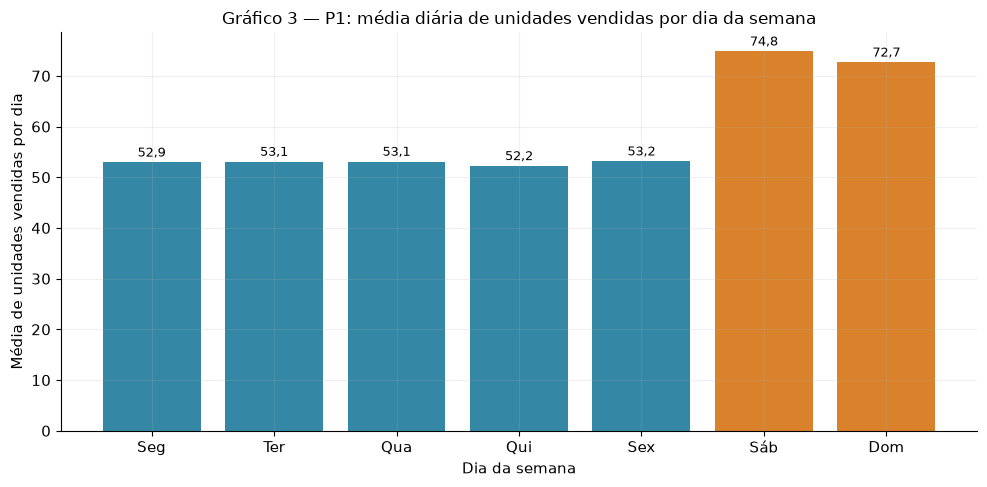

,Seg–Sex (média/dia),Sáb–Dom (média/dia),Aumento no fim de semana (%)
Store_ID,,,
ST01,18.7,25.6,36.8
ST02,16.8,24.5,46.0
ST03,17.4,23.7,35.9


P1: Sáb tem a maior média diária (74,8 unidades/dia).
Fim de semana: 73,8 unidades/dia contra 52,9 nos dias úteis (+39%); o padrão se repete nas três lojas.


In [5]:
# P1 — média por dia da semana: cada data entra uma vez (datas sem venda contariam como zero).
calendario = pd.date_range(df['Date'].min(), df['Date'].max(), freq='D')
vendas_dia = df.groupby('Date')['Quantity'].sum().reindex(calendario, fill_value=0)
semana = pd.DataFrame({'Date': calendario, 'unidades': vendas_dia.to_numpy()})
semana['dia'] = semana['Date'].dt.dayofweek
media_dia_semana = semana.groupby('dia')['unidades'].mean().reindex(range(7))
rotulos = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
melhor_dia = int(media_dia_semana.idxmax())
fig, ax = plt.subplots()
barras = ax.bar(rotulos, media_dia_semana, color=[COR_DESTAQUE if i >= 5 else COR for i in range(7)])
ax.bar_label(barras, labels=[br(v, 1) for v in media_dia_semana], fontsize=9, padding=2)
ax.set(xlabel='Dia da semana', ylabel='Média de unidades vendidas por dia',
       title='Gráfico 3 — P1: média diária de unidades vendidas por dia da semana')
fig.tight_layout(); fig.savefig(PASTA_GRAFICOS / '03_media_por_dia_semana.png'); plt.show()

media_util = semana.loc[semana['dia'] < 5, 'unidades'].mean()
media_fds = semana.loc[semana['dia'] >= 5, 'unidades'].mean()
aumento_fds = 100 * (media_fds / media_util - 1)
# Mesmo recorte por loja (P1 pede o comportamento em cada loja).
loja_dia = df.groupby(['Date', 'Store_ID'])['Quantity'].sum().unstack(fill_value=0).reindex(calendario, fill_value=0)
eh_fds = loja_dia.index.dayofweek >= 5
por_loja = pd.DataFrame({'Seg–Sex (média/dia)': loja_dia[~eh_fds].mean(),
                         'Sáb–Dom (média/dia)': loja_dia[eh_fds].mean()})
por_loja['Aumento no fim de semana (%)'] = 100 * (por_loja.iloc[:, 1] / por_loja.iloc[:, 0] - 1)
display(por_loja.round(1))
print(f'P1: {rotulos[melhor_dia]} tem a maior média diária ({br(media_dia_semana.iloc[melhor_dia], 1)} unidades/dia).')
print(f'Fim de semana: {br(media_fds, 1)} unidades/dia contra {br(media_util, 1)} nos dias úteis (+{br(aumento_fds, 0)}%);'
      ' o padrão se repete nas três lojas.')

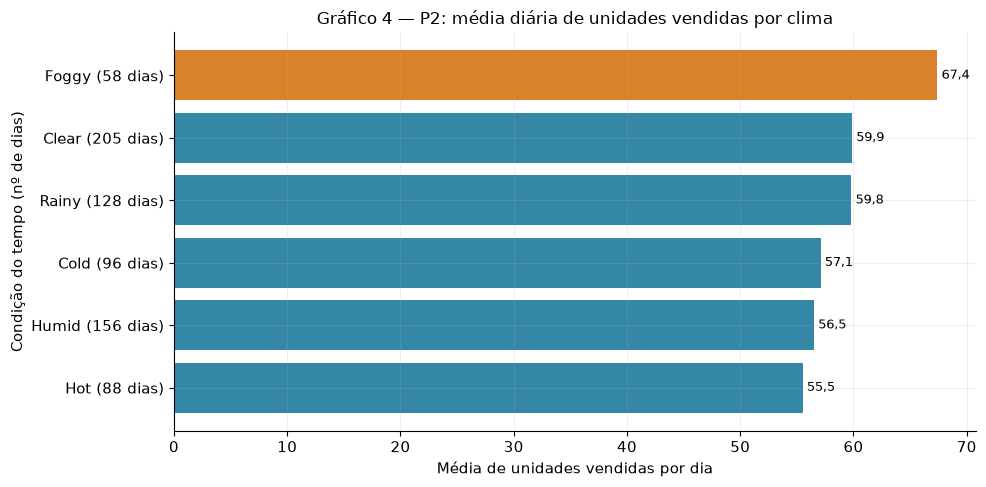

Dias em cada clima e % desses dias com festival (para avaliar representatividade e confusão):


,media_unidades,dias,pct_dias_festival
Weather,,,
Hot,55.5,88,4.5
Humid,56.5,156,8.3
Cold,57.1,96,10.4
Rainy,59.8,128,9.4
Clear,59.9,205,12.7
Foggy,67.4,58,12.1


P2: Foggy tem a maior média (67,41 unidades/dia), mas é o clima com menos dias (58) e 12,1% deles têm festival (média geral: 9,8%).
Interpretação: a diferença entre climas é uma ASSOCIAÇÃO e pode refletir festivais e estação; não demonstra causalidade.


In [6]:
# P2 — clima: uma linha por data, pois o clima é diário e se repete em cada item.
por_data = df.groupby('Date', as_index=False).agg(
    unidades=('Quantity', 'sum'), faturamento=('Total_Bill', 'sum'),
    Weather=('Weather', 'first'), Festival=('Festival', 'first'), Temperature=('Temperature', 'first'))
assert df.groupby('Date')['Weather'].nunique().max() == 1, 'Clima deveria ser único por data.'
por_data['tem_festival'] = por_data['Festival'].ne('No Festival')
clima = por_data.groupby('Weather').agg(media_unidades=('unidades', 'mean'), dias=('Date', 'count'),
                                        pct_dias_festival=('tem_festival', 'mean')).sort_values('media_unidades')
clima['pct_dias_festival'] *= 100
melhor_clima = clima['media_unidades'].idxmax()
fig, ax = plt.subplots()
rot_clima = [f'{c} ({d} dias)' for c, d in zip(clima.index, clima['dias'])]
barras = ax.barh(rot_clima, clima['media_unidades'],
                 color=[COR_DESTAQUE if c == melhor_clima else COR for c in clima.index])
ax.bar_label(barras, labels=[br(v, 1) for v in clima['media_unidades']], fontsize=9, padding=3)
ax.set(xlabel='Média de unidades vendidas por dia', ylabel='Condição do tempo (nº de dias)',
       title='Gráfico 4 — P2: média diária de unidades vendidas por clima')
fig.tight_layout(); fig.savefig(PASTA_GRAFICOS / '04_media_por_clima.png'); plt.show()
print('Dias em cada clima e % desses dias com festival (para avaliar representatividade e confusão):')
display(clima.round(1))
pct_fest_geral = 100 * por_data['tem_festival'].mean()
print(f'P2: {melhor_clima} tem a maior média ({br(clima.loc[melhor_clima, "media_unidades"], 2)} unidades/dia), mas é o clima com menos dias'
      f' ({int(clima.loc[melhor_clima, "dias"])}) e {br(clima.loc[melhor_clima, "pct_dias_festival"], 1)}% deles têm festival'
      f' (média geral: {br(pct_fest_geral, 1)}%).')
print('Interpretação: a diferença entre climas é uma ASSOCIAÇÃO e pode refletir festivais e estação; não demonstra causalidade.')

,count,mean,median,std
tem_festival,,,,
Sem festival,659,50.81,48.0,21.66
Com festival,72,132.58,132.0,33.51


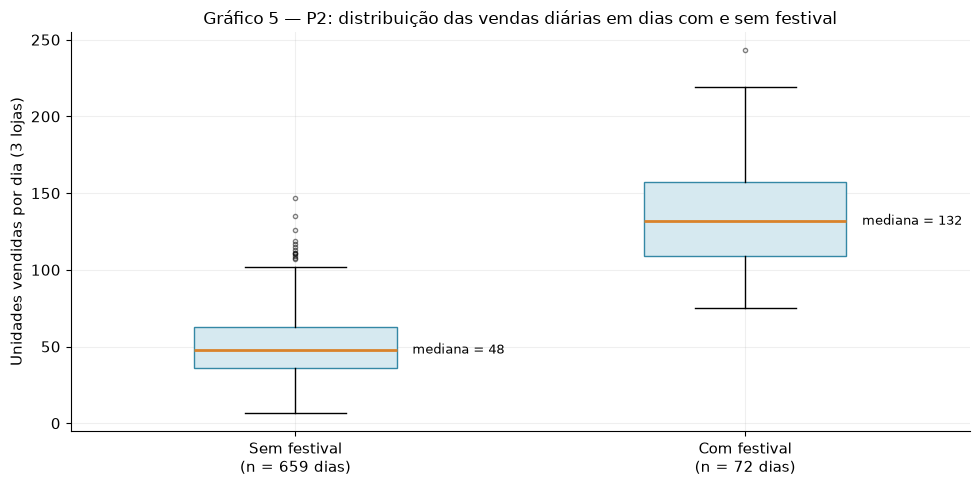

P2: a mediana em dias com festival é 2,75 vezes a dos dias sem festival (132 contra 48 unidades/dia).
Os grupos têm tamanhos muito diferentes (72 x 659 dias) e o resultado não isola o efeito do festival de outras condições.


In [7]:
# P2 — festivais: distribuição das vendas diárias com e sem festival.
festival_resumo = por_data.groupby('tem_festival')['unidades'].agg(['count', 'mean', 'median', 'std'])
display(festival_resumo.rename(index={False: 'Sem festival', True: 'Com festival'}).round(2))
grupos = [por_data.loc[~por_data['tem_festival'], 'unidades'], por_data.loc[por_data['tem_festival'], 'unidades']]
fig, ax = plt.subplots()
caixa = ax.boxplot(grupos, widths=.45, patch_artist=True,
                   medianprops={'color': COR_DESTAQUE, 'linewidth': 2},
                   flierprops={'marker': 'o', 'markersize': 3, 'alpha': .5})
for patch in caixa['boxes']:
    patch.set(facecolor='#d6e9f0', edgecolor=COR)
ax.set_xticks([1, 2], [f'Sem festival\n(n = {len(grupos[0])} dias)', f'Com festival\n(n = {len(grupos[1])} dias)'])
for i, g in enumerate(grupos, start=1):
    ax.text(i + .26, g.median(), f'mediana = {br(g.median())}', va='center', fontsize=9)
ax.set(ylabel='Unidades vendidas por dia (3 lojas)', xlabel='',
       title='Gráfico 5 — P2: distribuição das vendas diárias em dias com e sem festival')
fig.tight_layout(); fig.savefig(PASTA_GRAFICOS / '05_festival_boxplot.png'); plt.show()
razao_festival = festival_resumo.loc[True, 'median'] / festival_resumo.loc[False, 'median']
print(f'P2: a mediana em dias com festival é {br(razao_festival, 2)} vezes a dos dias sem festival'
      f' ({br(festival_resumo.loc[True, "median"])} contra {br(festival_resumo.loc[False, "median"])} unidades/dia).')
print('Os grupos têm tamanhos muito diferentes (72 x 659 dias) e o resultado não isola o efeito do festival de outras condições.')

,registros,unidades,qt_media_por_item,desconto_mediano,faturamento,lucro,margem_%,lucro_medio_por_item
grupo_promocao,,,,,,,,
Clearance,853,1801,2.11,23.30,93019.94,26763.46,28.77,31.38
Flash Sale,326,683,2.10,17.95,38553.38,12572.46,32.61,38.57
Festival,2183,6253,2.86,13.00,384456.50,140322.01,36.50,64.28
Combo,526,1196,2.27,10.55,70374.42,27628.43,39.26,52.53
Weekend,1607,3352,2.09,8.20,209143.62,84346.20,40.33,52.49
Desconto sem promoção,2089,4482,2.15,5.30,271227.12,114666.73,42.28,54.89
Sem desconto,11737,25260,2.15,0.00,1624031.07,737438.26,45.41,62.83


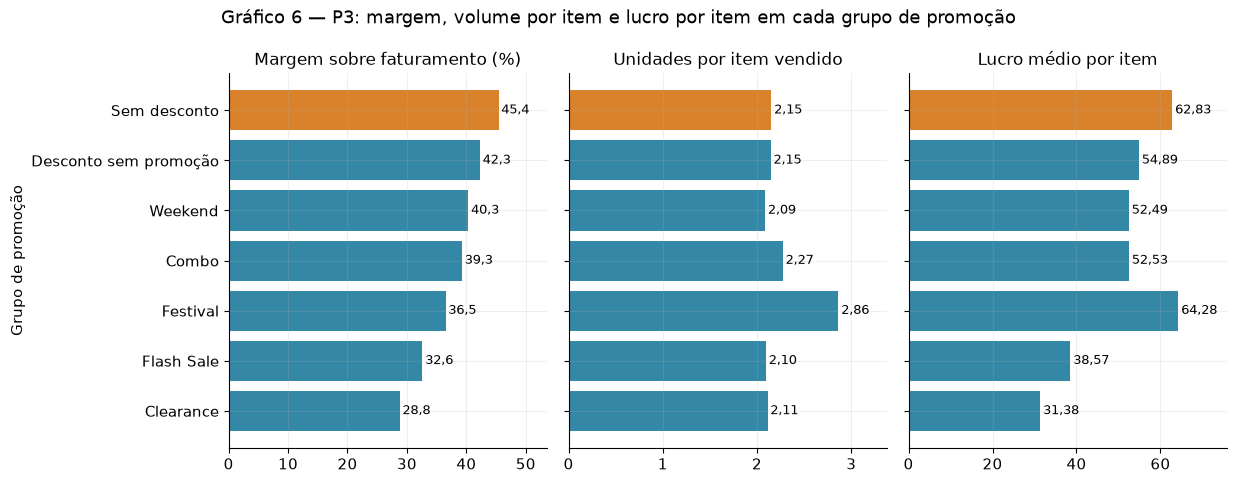

P3: maior margem: Sem desconto (45,41%); menor: Clearance (28,77%).
Só a promoção Festival aumenta o volume por item (2,86 contra 2,15 sem desconto) e chega a um lucro médio por item de 64,28 (sem desconto: 62,83).
Clearance, Flash Sale, Weekend e Combo vendem praticamente as mesmas unidades por item que os itens sem desconto, então a margem menor não é compensada por volume.
Cuidado: promoções não foram randomizadas (a promoção Festival coincide com dias de festival) e Profit não deduz o descarte.


In [8]:
# P3 — promoções: separar desconto sem promoção dos itens sem desconto, como decidido no RA1.
df_promo = df.copy()
condicoes = [df_promo['Promotion_Applied'].eq(True), df_promo['Discount_Without_Promotion'].eq(True)]
df_promo['grupo_promocao'] = np.select(
    condicoes, [df_promo['Promotion_Type'], 'Desconto sem promoção'], default='Sem desconto')
promo = df_promo.groupby('grupo_promocao').agg(
    registros=('Quantity', 'size'), unidades=('Quantity', 'sum'),
    qt_media_por_item=('Quantity', 'mean'), desconto_mediano=('Discount_Percentage', 'median'),
    faturamento=('Total_Bill', 'sum'), lucro=('Profit', 'sum'))
promo['margem_%'] = 100 * promo['lucro'] / promo['faturamento']
promo['lucro_medio_por_item'] = promo['lucro'] / promo['registros']
promo = promo.sort_values('margem_%')
display(promo.round(2))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.9), sharey=True)
metricas_p3 = [('margem_%', 'Margem sobre faturamento (%)', 1),
               ('qt_media_por_item', 'Unidades por item vendido', 2),
               ('lucro_medio_por_item', 'Lucro médio por item', 2)]
for ax, (col, titulo, casas) in zip(axes, metricas_p3):
    cores = [COR_DESTAQUE if g == 'Sem desconto' else COR for g in promo.index]
    barras = ax.barh(promo.index, promo[col], color=cores)
    ax.bar_label(barras, labels=[br(v, casas) for v in promo[col]], fontsize=9, padding=2)
    ax.set(title=titulo, xlabel='')
    ax.set_xlim(0, promo[col].max() * 1.18)
axes[0].set_ylabel('Grupo de promoção')
fig.suptitle('Gráfico 6 — P3: margem, volume por item e lucro por item em cada grupo de promoção', fontsize=13)
fig.tight_layout(); fig.savefig(PASTA_GRAFICOS / '06_promocoes_margem_unidades.png'); plt.show()

melhor_promo = promo['margem_%'].idxmax()
sem = promo.loc['Sem desconto']
fest = promo.loc['Festival']
print(f"P3: maior margem: {melhor_promo} ({br(promo['margem_%'].max(), 2)}%); menor: {promo['margem_%'].idxmin()} ({br(promo['margem_%'].min(), 2)}%).")
print(f"Só a promoção Festival aumenta o volume por item ({br(fest['qt_media_por_item'], 2)} contra {br(sem['qt_media_por_item'], 2)} sem desconto)"
      f" e chega a um lucro médio por item de {br(fest['lucro_medio_por_item'], 2)} (sem desconto: {br(sem['lucro_medio_por_item'], 2)}).")
print('Clearance, Flash Sale, Weekend e Combo vendem praticamente as mesmas unidades por item que os itens sem desconto,'
      ' então a margem menor não é compensada por volume.')
print('Cuidado: promoções não foram randomizadas (a promoção Festival coincide com dias de festival) e Profit não deduz o descarte.')

,count,mean,median,std
Perishability,,,,
Low,6001,33.45,33.3,12.02
Medium,2093,37.13,33.3,11.36
High,5264,34.95,33.3,12.16
Very High,5963,32.99,33.3,14.10


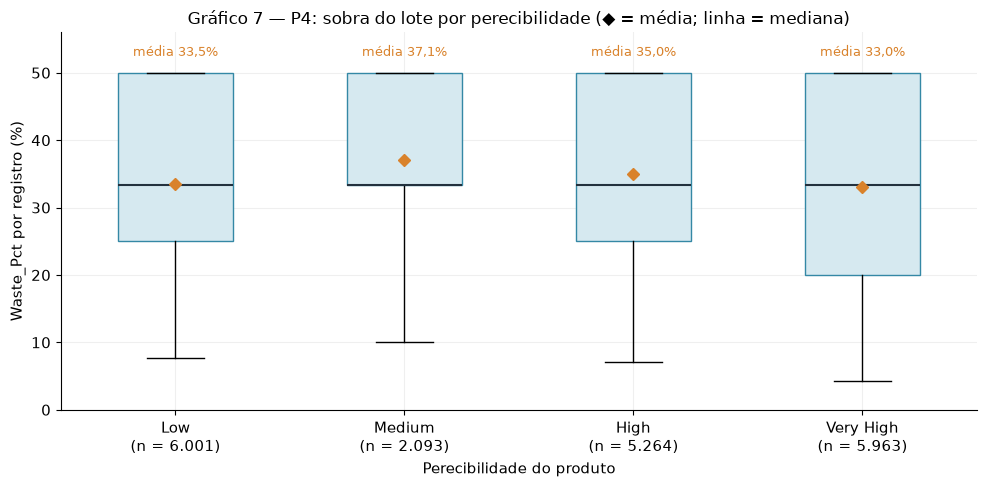

Sobra por categoria:


,registros,media,mediana
Category,,,
Cakes,2189,43.16,50.0
Beverages,3219,37.31,33.3
Dairy & Spreads,3620,37.22,33.3
Pastry & Sweet,3577,33.49,33.3
Bread & Daily,2648,31.73,33.3
Indian Bakery,3058,27.65,25.0
Savoury Bakery,1010,21.31,20.0


Produtos com maiores percentuais registrados de sobra:


,registros,mediana_sobra,media_sobra
Product,,,
Peanut Butter,199,50.0,47.16
Jam,354,50.0,46.09
Pineapple Cake,307,50.0,45.99
Butterscotch Cake,312,50.0,45.79
Honey,243,50.0,45.78
Black Forest Cake,419,50.0,44.89
Chocolate Cake,621,50.0,43.39
Chocolate Muffin,360,50.0,40.52


P4: as medianas são iguais (33,3%), mas as médias variam de 33,0% (Very High) a 37,1% (Medium).
Os produtos mais perecíveis NÃO têm a maior sobra média; os bolos e alguns itens de mercearia lideram a sobra mediana (50%).
Os resultados são ponderados pelo número de linhas de venda; falta um ID de lote para estimar a perda total real.


In [9]:
# P4 — sobra por perecibilidade: distribuição completa + média, sem somar unidades de lotes não identificados.
ordem = ['Low', 'Medium', 'High', 'Very High']
sobra = df.groupby('Perishability')['Waste_Pct'].agg(['count', 'mean', 'median', 'std']).reindex(ordem)
display(sobra.round(2))
fig, ax = plt.subplots()
dados_sobra = [df.loc[df['Perishability'] == p, 'Waste_Pct'] for p in ordem]
caixa = ax.boxplot(dados_sobra, widths=.5, patch_artist=True, showmeans=True,
                   medianprops={'color': '#23313e', 'linewidth': 1.5},
                   meanprops={'marker': 'D', 'markerfacecolor': COR_DESTAQUE, 'markeredgecolor': COR_DESTAQUE},
                   flierprops={'marker': 'o', 'markersize': 3, 'alpha': .4})
for patch in caixa['boxes']:
    patch.set(facecolor='#d6e9f0', edgecolor=COR)
for i, p in enumerate(ordem, start=1):
    ax.text(i, 52.5, f"média {br(sobra.loc[p, 'mean'], 1)}%", ha='center', fontsize=9, color=COR_DESTAQUE)
ax.set_xticks(range(1, 5), [f"{p}\n(n = {br(sobra.loc[p, 'count'])})" for p in ordem])
ax.set_ylim(0, 56)
ax.set(xlabel='Perecibilidade do produto', ylabel='Waste_Pct por registro (%)',
       title='Gráfico 7 — P4: sobra do lote por perecibilidade (◆ = média; linha = mediana)')
fig.tight_layout(); fig.savefig(PASTA_GRAFICOS / '07_sobra_perecibilidade.png'); plt.show()

sobra_categoria = (df.groupby('Category')['Waste_Pct'].agg(registros='size', media='mean', mediana='median')
                   .sort_values('media', ascending=False))
print('Sobra por categoria:')
display(sobra_categoria.round(2))
produtos_sobra = (df.groupby('Product')['Waste_Pct']
                  .agg(registros='size', mediana_sobra='median', media_sobra='mean')
                  .sort_values(['mediana_sobra', 'media_sobra'], ascending=False).head(8))
print('Produtos com maiores percentuais registrados de sobra:')
display(produtos_sobra.round(2))
mais_sobra = sobra['mean'].idxmax(); menos_sobra = sobra['mean'].idxmin()
print(f"P4: as medianas são iguais (33,3%), mas as médias variam de {br(sobra['mean'].min(), 1)}% ({menos_sobra}) a {br(sobra['mean'].max(), 1)}% ({mais_sobra}).")
print('Os produtos mais perecíveis NÃO têm a maior sobra média; os bolos e alguns itens de mercearia lideram a sobra mediana (50%).')
print('Os resultados são ponderados pelo número de linhas de venda; falta um ID de lote para estimar a perda total real.')

## 3. Amostragem e representatividade

- **Origem:** dataset **sintético** “Bakery Sales, Customer & Inventory Analytics Dataset”, publicado no Kaggle por `sdcloud` (licença CC0), criado para fins educacionais.
- **Abrangência:** 19.321 itens de 6.576 pedidos, 3 lojas, 7 categorias, 35 produtos e 500 clientes, de 01/01/2023 a 31/12/2024 (731 dias, todos com vendas).
- **Seleção:** usamos **todos os registros** preparados no RA1 (censo da base); não foi feita amostragem.
- **Adequação ao problema:** a base tem exatamente as variáveis que o problema pede (hora, data, clima, festival, promoção, lucro e sobra), por isso serve para explorar as perguntas P1–P4 e testar um modelo de previsão.
- **Limitações e vieses:** (1) os padrões vêm de um gerador artificial — o modelo pode estar “aprendendo as regras do gerador”, e os resultados não se generalizam automaticamente para padarias reais; (2) os grupos são desiguais (72 dias com festival contra 659; só 58 dias de neblina); (3) `Waste_Pct` é do lote, mas aparece em cada linha de venda — produtos que vendem mais pesam mais; (4) não há registro de rupturas de estoque, então vendas ≠ demanda; (5) localização das lojas e moeda não são informadas; (6) o clima é diário, não por hora.

O modelo abaixo usa um recorte **temporal**: o período de teste é sempre posterior ao de treino, o que se aproxima de prever vendas futuras.

## 4. Machine Learning — regressão de vendas por loja e categoria (um dia à frente)

**Problema preditivo:** estimar quantas unidades serão **registradas como vendidas** no dia seguinte em cada loja e categoria, usando apenas informação conhecida até o dia anterior mais o calendário do dia previsto. Isso apoia o planejamento da produção diária, mas não é a demanda latente nem a produção ótima.

- **Target:** `unidades` = soma de `Quantity` no dia, loja e categoria.
- **Features:** `Store_ID`, `Category`, dia da semana, mês, indicação de festival (conhecida pelo calendário), vendas da véspera (`lag_1`), vendas de sete dias antes (`lag_7`) e médias dos sete e dos 28 dias **anteriores**.
- **Painel completo:** todos os dias × lojas × categorias; se uma combinação não teve vendas em um dia, recebe zero unidades.
- **Separação treino/teste:** treino até 30/09/2024 e teste de 01/10/2024 a 31/12/2024, sem embaralhar (respeita a ordem do tempo).
- **Modelo:** Random Forest Regressor (120 árvores, profundidade máxima 12), com One-Hot para loja e categoria.
- **Métricas:** MAE (erro médio em unidades, fácil de explicar), RMSE (penaliza erros grandes) e R²; comparação com uma **referência simples**: repetir a média dos sete dias anteriores.

**Importante:** no teste, os lags são recalculados a partir das vendas observadas nos dias anteriores. É uma previsão sequencial de **um dia à frente**, com atualização diária — não uma previsão de meses inteiros sem dados novos.

In [10]:
# Painel diário completo: permite aprender também os dias sem registro de vendas.
datas = pd.date_range(df['Date'].min(), df['Date'].max(), freq='D')
lojas = sorted(df['Store_ID'].unique())
categorias = sorted(df['Category'].unique())
indice = pd.MultiIndex.from_product([lojas, categorias, datas], names=['Store_ID', 'Category', 'Date'])
vendas = df.groupby(['Store_ID', 'Category', 'Date'])['Quantity'].sum()
painel = vendas.reindex(indice, fill_value=0).rename('unidades').reset_index()
painel = painel.sort_values(['Store_ID', 'Category', 'Date']).reset_index(drop=True)
painel['dia_semana'] = painel['Date'].dt.dayofweek
painel['mes'] = painel['Date'].dt.month
# Datas de festivais vêm do calendário da base; condições reais futuras do tempo NÃO são usadas.
calendario_festival = df.groupby('Date')['Festival'].first().ne('No Festival')
painel['festival'] = painel['Date'].map(calendario_festival).fillna(False).astype(int)
serie = painel.groupby(['Store_ID', 'Category'])['unidades']
painel['lag_1'] = serie.shift(1)
painel['lag_7'] = serie.shift(7)
painel['media_7'] = serie.transform(lambda x: x.shift(1).rolling(7, min_periods=7).mean())
painel['media_28'] = serie.transform(lambda x: x.shift(1).rolling(28, min_periods=28).mean())
# Os primeiros 28 dias de cada série não têm histórico suficiente e são excluídos.
painel = painel.dropna(subset=['lag_1', 'lag_7', 'media_7', 'media_28']).reset_index(drop=True)
features_categoricas = ['Store_ID', 'Category']
features_numericas = ['dia_semana', 'mes', 'festival', 'lag_1', 'lag_7', 'media_7', 'media_28']
features = features_categoricas + features_numericas
corte = pd.Timestamp('2024-10-01')
treino = painel['Date'] < corte
teste = painel['Date'] >= corte
X_train, X_test = painel.loc[treino, features], painel.loc[teste, features]
y_train, y_test = painel.loc[treino, 'unidades'], painel.loc[teste, 'unidades']
assert len(X_train) and len(X_test) and painel.loc[treino, 'Date'].max() < painel.loc[teste, 'Date'].min()
print('Registros de treino:', len(X_train), '| teste:', len(X_test))
print('Treino até:', painel.loc[treino, 'Date'].max().date(),
      '| Teste de:', painel.loc[teste, 'Date'].min().date(), 'a', painel.loc[teste, 'Date'].max().date())
print(f'Alvo no teste: média {br(y_test.mean(), 2)} unidades, mediana {br(y_test.median())}, '
      f'{br(100 * y_test.eq(0).mean(), 1)}% de zeros, máximo {br(y_test.max())}.')

Registros de treino: 12831 | teste: 1932
Treino até: 2024-09-30 | Teste de: 2024-10-01 a 2024-12-31
Alvo no teste: média 2,87 unidades, mediana 1, 37,6% de zeros, máximo 37.


In [11]:
processador = ColumnTransformer(
    transformers=[('categoricas', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_categoricas),
                  ('numericas', 'passthrough', features_numericas)])
modelo = Pipeline(steps=[('preprocessamento', processador),
                         ('floresta', RandomForestRegressor(n_estimators=120, max_depth=12,
                          min_samples_leaf=4, random_state=42, n_jobs=-1))])
modelo.fit(X_train, y_train)
previsto = np.maximum(modelo.predict(X_test), 0)
# Referência: prever a média de venda dos sete dias anteriores da mesma loja/categoria.
base = X_test['media_7'].to_numpy()


def avaliar(y, p):
    return {'MAE (unidades)': mean_absolute_error(y, p),
            'RMSE (unidades)': np.sqrt(mean_squared_error(y, p)),
            'R²': r2_score(y, p)}


metricas = pd.DataFrame({'Random Forest': avaliar(y_test, previsto),
                         'Referência (média 7 dias)': avaliar(y_test, base)}).T
print('Avaliação no período de teste, nunca usado no treinamento:')
display(metricas.round(3))
mae_modelo = metricas.loc['Random Forest', 'MAE (unidades)']
mae_base = metricas.loc['Referência (média 7 dias)', 'MAE (unidades)']
ganho_mae = 100 * (mae_base - mae_modelo) / mae_base
mae_relativo = 100 * mae_modelo / y_test.mean()
print(f'Variação do MAE frente à referência: {ganho_mae:+.1f}% (positivo = modelo com menor erro).')
print(f'Contexto: o MAE de {br(mae_modelo, 3)} unidades equivale a {br(mae_relativo, 0)}% da venda média de um grupo loja/categoria/dia'
      f' ({br(y_test.mean(), 2)} unidades) — erro ainda alto em termos relativos.')
if ganho_mae <= 0:
    print('Conclusão: o modelo não superou a referência simples em MAE neste teste; não justificaria adoção sem revisão.')
else:
    print('Conclusão: o modelo teve MAE e RMSE menores que a referência e R² positivo, mas isso não garante desempenho em dados reais.')

Avaliação no período de teste, nunca usado no treinamento:


,MAE (unidades),RMSE (unidades),R²
Random Forest,2.526,3.727,0.203
Referência (média 7 dias),2.801,4.217,-0.020


Variação do MAE frente à referência: +9.8% (positivo = modelo com menor erro).
Contexto: o MAE de 2,526 unidades equivale a 88% da venda média de um grupo loja/categoria/dia (2,87 unidades) — erro ainda alto em termos relativos.
Conclusão: o modelo teve MAE e RMSE menores que a referência e R² positivo, mas isso não garante desempenho em dados reais.


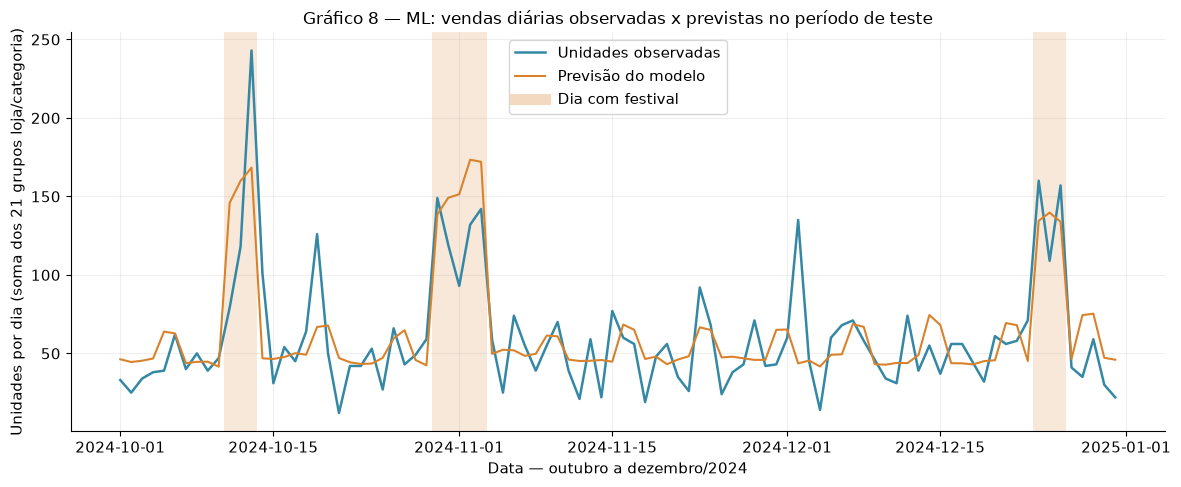

Erro médio por tipo de dia (teste):


,MAE modelo,MAE referência,Venda média
festival,,,
Dias sem festival,2.23,2.51,2.37
Dias com festival,4.68,4.98,6.50


Categorias com MAIOR erro absoluto médio (teste):


Category
Indian Bakery      4.64
Bread & Daily      3.30
Pastry & Sweet     2.51
Savoury Bakery     2.27
Dairy & Spreads    2.04
Name: erro_absoluto, dtype: float64

Importância das variáveis no Random Forest (% da redução de impureza; One-Hot somado por variável):


,importância (%)
Category,19.1
media_28,19.0
festival,15.7
media_7,12.9
lag_1,7.9
dia_semana,7.5
mes,7.0
lag_7,6.9
Store_ID,3.9


Interpretação: o modelo acompanha o nível de cada série (médias e lags) e os picos de festival, mas suaviza dias extremos; as previsões são contínuas e precisariam de regra de arredondamento e estoque de segurança para virar produção.


In [12]:
# Padrões do erro, importância das variáveis e gráfico do período de teste.
comparacao = painel.loc[teste, ['Date', 'Store_ID', 'Category', 'festival', 'unidades']].copy()
comparacao['previsto'] = previsto
comparacao['referencia'] = base
comparacao['erro_absoluto'] = (comparacao['unidades'] - comparacao['previsto']).abs()
comparacao['erro_referencia'] = (comparacao['unidades'] - comparacao['referencia']).abs()
resumo_dia = comparacao.groupby('Date')[['unidades', 'previsto', 'referencia']].sum()
dias_festival_teste = comparacao.groupby('Date')['festival'].max()

fig, ax = plt.subplots(figsize=(12, 5))
for d in dias_festival_teste[dias_festival_teste == 1].index:
    meio_dia = np.timedelta64(12, 'h')
    ax.axvspan(d.to_datetime64() - meio_dia, d.to_datetime64() + meio_dia, color='#f3d9c0', alpha=.6, lw=0)
ax.plot(resumo_dia.index, resumo_dia['unidades'], label='Unidades observadas', color=COR, linewidth=1.8)
ax.plot(resumo_dia.index, resumo_dia['previsto'], label='Previsão do modelo', color=COR_DESTAQUE, linewidth=1.5)
ax.plot([], [], color='#f3d9c0', linewidth=8, label='Dia com festival')
ax.set(xlabel='Data — outubro a dezembro/2024', ylabel='Unidades por dia (soma dos 21 grupos loja/categoria)',
       title='Gráfico 8 — ML: vendas diárias observadas x previstas no período de teste')
ax.legend(); fig.tight_layout(); fig.savefig(PASTA_GRAFICOS / '08_ml_observado_previsto.png'); plt.show()

erro_por_tipo = comparacao.groupby('festival')[['erro_absoluto', 'erro_referencia', 'unidades']].mean()
erro_por_tipo.index = erro_por_tipo.index.map({0: 'Dias sem festival', 1: 'Dias com festival'})
erro_por_tipo.columns = ['MAE modelo', 'MAE referência', 'Venda média']
print('Erro médio por tipo de dia (teste):')
display(erro_por_tipo.round(2))
print('Categorias com MAIOR erro absoluto médio (teste):')
erro_categoria = comparacao.groupby('Category')['erro_absoluto'].mean().sort_values(ascending=False)
display(erro_categoria.head().round(2))

nomes = modelo.named_steps['preprocessamento'].get_feature_names_out()
importancias = pd.Series(modelo.named_steps['floresta'].feature_importances_, index=nomes)
grupo = importancias.index.str.replace(r'^categoricas__(Store_ID|Category)_.*$', r'\1', regex=True)
grupo = grupo.str.replace('numericas__', '', regex=False)
importancia_agrupada = (100 * importancias.groupby(grupo).sum()).sort_values(ascending=False)
print('Importância das variáveis no Random Forest (% da redução de impureza; One-Hot somado por variável):')
display(importancia_agrupada.round(1).to_frame('importância (%)'))
print('Interpretação: o modelo acompanha o nível de cada série (médias e lags) e os picos de festival,'
      ' mas suaviza dias extremos; as previsões são contínuas e precisariam de regra de arredondamento e estoque de segurança para virar produção.')

## 5. Testes de consistência

Verificações automáticas para garantir que os resultados acima são confiáveis. Se algum teste falhar, a célula interrompe a execução com uma mensagem explicando o problema.

1. **Sem vazamento de dados:** `lag_1`, `lag_7`, `media_7` e `media_28` são recalculados de forma independente a partir das vendas dos dias **anteriores** e comparados com o painel.
2. **Divisão temporal correta:** todo o treino é anterior ao teste, e o teste cobre 92 dias × 21 grupos.
3. **Target fora das features** e previsões válidas (finitas e não negativas).
4. **Integridade da base e das saídas:** 19.321 registros, chave única e os 8 gráficos gravados.

In [13]:
completo = vendas.reindex(indice, fill_value=0)


def vendas_dias_antes(k):
    dias = painel['Date'].to_numpy() - np.timedelta64(k, 'D')
    chave = pd.MultiIndex.from_arrays([painel['Store_ID'], painel['Category'], dias])
    return completo.reindex(chave).to_numpy()


testes = {}
testes['lag_1 = venda do dia anterior'] = np.allclose(painel['lag_1'], vendas_dias_antes(1))
testes['lag_7 = venda de 7 dias antes'] = np.allclose(painel['lag_7'], vendas_dias_antes(7))
testes['media_7 usa só os 7 dias anteriores'] = np.allclose(
    painel['media_7'], np.mean([vendas_dias_antes(k) for k in range(1, 8)], axis=0))
testes['media_28 usa só os 28 dias anteriores'] = np.allclose(
    painel['media_28'], np.mean([vendas_dias_antes(k) for k in range(1, 29)], axis=0))
testes['treino termina antes do teste'] = painel.loc[treino, 'Date'].max() < painel.loc[teste, 'Date'].min()
testes['teste = 92 dias x 21 grupos'] = len(X_test) == 92 * len(lojas) * len(categorias)
testes['target fora das features'] = 'unidades' not in features
testes['previsões finitas e >= 0'] = bool(np.isfinite(previsto).all() and (previsto >= 0).all())
testes['métricas finitas'] = bool(np.isfinite(metricas.to_numpy()).all())
testes['base com 19.321 registros e chave única'] = len(df) == 19321 and not df.duplicated(['Order_ID', 'Product']).any()
graficos_esperados = ['01_distribuicao_variaveis.png', '02_unidades_por_hora.png', '03_media_por_dia_semana.png',
                      '04_media_por_clima.png', '05_festival_boxplot.png', '06_promocoes_margem_unidades.png',
                      '07_sobra_perecibilidade.png', '08_ml_observado_previsto.png']
testes['8 gráficos gravados em outputs/graficos'] = all((PASTA_GRAFICOS / g).is_file() for g in graficos_esperados)

resultado_testes = pd.Series(testes).map({True: 'OK', False: 'FALHOU'}).rename('resultado').to_frame()
display(resultado_testes)
falhas = [nome for nome, ok in testes.items() if not ok]
assert not falhas, f'Testes com falha: {falhas}'
print(f'Todos os {len(testes)} testes passaram.')

,resultado
lag_1 = venda do dia anterior,OK
lag_7 = venda de 7 dias antes,OK
media_7 usa só os 7 dias anteriores,OK
media_28 usa só os 28 dias anteriores,OK
treino termina antes do teste,OK
teste = 92 dias x 21 grupos,OK
target fora das features,OK
previsões finitas e >= 0,OK
métricas finitas,OK
base com 19.321 registros e chave única,OK


Todos os 11 testes passaram.


## 6. Conclusões

**Estatística e visualizações.** Os itens vendidos são pequenos (mediana de 2 unidades; 75% têm até 2) e o faturamento é assimétrico, com média (139,27) bem acima da mediana (82,80). As vendas se concentram em dois picos diários (9h e 17h) e crescem cerca de 40% nos fins de semana, nas três lojas. Dias de festival têm mediana de vendas 2,75 vezes maior (132 contra 48 unidades/dia). A neblina aparece com a maior média por clima, mas é o clima com menos dias e mais festivais — associação, não causa. Nas promoções, os itens sem desconto têm a maior margem (45,4%) e só a promoção Festival aumenta o volume por item o suficiente para manter o lucro médio por item. A sobra mediana é igual (33,3%) em todos os níveis de perecibilidade; as médias mostram que os mais perecíveis não são os que mais sobram.

**Machine Learning.** O Random Forest obteve MAE de 2,526 unidades por loja/categoria/dia, contra 2,801 da referência (−9,8%), RMSE de 3,727 contra 4,217 e R² de 0,203 contra −0,020. Há ganho mensurável, mas o erro ainda é alto em relação à venda média (2,87 unidades) e o modelo suaviza os picos.

**Limitações.** Base sintética; clima diário; sem localização, moeda, ID de lote ou rupturas de estoque; promoções e festivais não são experimentos controlados.

**Relação com o problema.** Os resultados indicam *quando* produzir mais (manhã, fim da tarde, fins de semana e festivais), *quais promoções* sacrificam margem sem ganho de volume (Clearance, Flash Sale) e oferecem uma previsão de curto prazo melhor que a média simples para apoiar a produção diária. Não constituem ainda uma política ótima de produção.

A célula abaixo gera `outputs/ra3_resultados.md` com os números calculados nesta execução.

In [14]:
# Documento final gerado apenas com os valores efetivamente calculados acima.
sem_d = promo.loc['Sem desconto']
fest_p = promo.loc['Festival']
resumo = f"""# RA3 — Resultados do projeto: padarias

Equipe: Helena Picinin, Marco Capote, Raissa Queiroz e Rafael Sene.

## Origem e representatividade
Base sintética do Kaggle, {br(len(df))} itens de pedidos; {br(df.Order_ID.nunique())} pedidos distintos; {df.Store_ID.nunique()} lojas; {df.Category.nunique()} categorias; {df.Product.nunique()} produtos; período de {df.Date.min():%d/%m/%Y} a {df.Date.max():%d/%m/%Y}. Censo dos registros disponíveis, não amostragem. Não generalizável diretamente a padarias reais; grupos desiguais (72 dias com festival, 58 dias de neblina).

## Estatística descritiva
| Variável por item | Média | Mediana | Desvio-padrão | Mín. | Q1 | Q3 | Máx. | Amplitude |
|---|---|---|---|---|---|---|---|---|
""" + ''.join(
    f"| {nome} | {br(estat.loc[v, 'mean'], 2)} | {br(estat.loc[v, 'median'], 2)} | {br(estat.loc[v, 'std'], 2)} | {br(estat.loc[v, 'min'], 2)} | "
    f"{br(estat.loc[v, 'q1'], 2)} | {br(estat.loc[v, 'q3'], 2)} | {br(estat.loc[v, 'max'], 2)} | {br(estat.loc[v, 'amplitude'], 2)} |\n"
    for v, nome in [('Quantity', 'Quantidade (unidades)'), ('Total_Bill', 'Faturamento'), ('Profit', 'Lucro'), ('Waste_Pct', 'Waste_Pct (%)')]
) + f"""
- Distribuição: {br(pct_qtd.loc[1], 1)}% dos itens têm 1 unidade e {br(pct_ate_2, 1)}% até 2; faturamento com assimetria {br(estat.loc['Total_Bill', 'assimetria'], 2)}; {br(pct_sobra_50, 1)}% dos registros têm Waste_Pct = 50%.

## Visualizações e interpretações
1. `01_distribuicao_variaveis.png`: quantidade e faturamento com cauda longa à direita; sobra concentrada em poucos valores (lotes pequenos).
2. `02_unidades_por_hora.png`: pico às {hora_pico}h ({br(por_hora.loc[hora_pico, 'unidades'])} unidades) e às {hora_pico_tarde}h; 8h–10h = {br(pct_manha, 1)}% e 16h–18h = {br(pct_tarde, 1)}% das unidades.
3. `03_media_por_dia_semana.png`: maior média em {rotulos[melhor_dia]} ({br(media_dia_semana.iloc[melhor_dia], 1)} unidades/dia); fim de semana +{br(aumento_fds, 0)}% sobre os dias úteis, nas três lojas.
4. `04_media_por_clima.png`: maior média em {melhor_clima} ({br(clima.loc[melhor_clima, 'media_unidades'], 2)} unidades/dia; {int(clima.loc[melhor_clima, 'dias'])} dias; {br(clima.loc[melhor_clima, 'pct_dias_festival'], 1)}% com festival). Associação, sem inferência causal.
5. `05_festival_boxplot.png`: medianas de {br(festival_resumo.loc[True, 'median'])} (com festival, n = {int(festival_resumo.loc[True, 'count'])}) e {br(festival_resumo.loc[False, 'median'])} (sem festival, n = {int(festival_resumo.loc[False, 'count'])}) unidades/dia; razão de {br(razao_festival, 2)}.
6. `06_promocoes_margem_unidades.png`: maior margem em {melhor_promo} ({br(promo.loc[melhor_promo, 'margem_%'], 2)}%); só a promoção Festival aumenta unidades por item ({br(fest_p['qt_media_por_item'], 2)} contra {br(sem_d['qt_media_por_item'], 2)}) e mantém o lucro médio por item ({br(fest_p['lucro_medio_por_item'], 2)} contra {br(sem_d['lucro_medio_por_item'], 2)}).
7. `07_sobra_perecibilidade.png`: medianas iguais (33,3%); médias de {br(sobra['mean'].min(), 1)}% ({menos_sobra}) a {br(sobra['mean'].max(), 1)}% ({mais_sobra}).
8. `08_ml_observado_previsto.png`: a previsão acompanha o nível e os festivais, mas suaviza os picos.

## Machine Learning supervisionado — regressão
- Alvo: unidades vendidas registradas por data, loja e categoria.
- Entradas: loja, categoria, calendário, festival e lags/médias de vendas passadas.
- Treino: {int(treino.sum())} observações anteriores a 01/10/2024; teste: {int(teste.sum())} observações posteriores (out–dez/2024).
- Modelo: Random Forest Regressor; referência: média dos 7 dias anteriores.

| Métrica | Random Forest | Referência |
|---|---|---|
| MAE (unidades) | {br(mae_modelo, 3)} | {br(mae_base, 3)} |
| RMSE (unidades) | {br(metricas.loc['Random Forest', 'RMSE (unidades)'], 3)} | {br(metricas.loc['Referência (média 7 dias)', 'RMSE (unidades)'], 3)} |
| R² | {br(metricas.loc['Random Forest', 'R²'], 3)} | {br(metricas.loc['Referência (média 7 dias)', 'R²'], 3)} |

- Redução do MAE: {br(ganho_mae, 1)}%. Venda média no teste: {br(y_test.mean(), 2)} unidades por grupo/dia (MAE = {br(mae_relativo, 0)}% dessa média).
- Interpretação: {'o modelo superou a referência simples no recorte de teste, mas ainda erra bastante em termos relativos e suaviza picos.' if ganho_mae > 0 else 'o modelo NÃO superou a referência simples em MAE; precisa de revisão antes de qualquer uso prático.'}

## Testes de consistência
{len(testes)} verificações automáticas aprovadas (sem vazamento de dados nos lags, divisão temporal correta, previsões válidas, base íntegra e gráficos gravados).

## Limitações e conclusão
A base é sintética; clima é diário; não há localização das lojas, moeda, ID de lote, rupturas de estoque nem perdas observadas por produto. O projeto mostra quando produzir mais (manhã, fim da tarde, fins de semana e festivais), quais promoções reduzem margem sem ganho de volume e uma previsão de curto prazo melhor que a média simples; não fornece ainda uma política comprovada de produção ótima.

Fonte: sdcloud, Bakery Sales, Customer & Inventory Analytics Dataset, Kaggle. https://www.kaggle.com/datasets/sdcloud/historical-bakery-sales-dataset
"""
ARQUIVO_RESULTADOS = PASTA_SAIDA / 'ra3_resultados.md'
ARQUIVO_RESULTADOS.write_text(resumo, encoding='utf-8')
print('Relatório gerado:', ARQUIVO_RESULTADOS)
print('Gráficos gerados:', len(list(PASTA_GRAFICOS.glob('*.png'))))

Relatório gerado: outputs\ra3_resultados.md
Gráficos gerados: 8
